## MeshLab Tutorial

Generate a boundary-layer mesh around a circular contour

### 1. Import packages
---

In [1]:
import numpy as np

from copy import deepcopy

from meshlab.data import Mesh, Contour
from meshlab.operations import insert_contour, compute_normals, advance_front
from meshlab.visualization import plot_mesh

### 2. Define parameters
---

In [2]:
num_points = 100            # Number of surface points
num_layers = 10             # Number of layers
height = 0.1                # First layer height
growth_rate = 1.1           # Ratio between two consecutive layers

### 3. Geometry definition
---

In [3]:
# Define angles between 0 and 2 * pi - remove the last point
alpha = np.linspace(0.0, 2.0 * np.pi, num_points, endpoint=False)

# Define a circle with points ordered in the counter-clockwise direction
points = np.column_stack(
    [
        np.cos(alpha),      # x
        np.sin(alpha),      # y
    ]
)

### 4. Create boudary layer mesh
---

Initialize mesh, surface and front

In [4]:
# Initialize mesh and surface
mesh = Mesh()
surface = Contour("Surface")

# Insert contour into mesh
insert_contour(mesh, surface, points)

# Create front based on surface
front = deepcopy(surface)
front.name = "Front"

Create the first layer

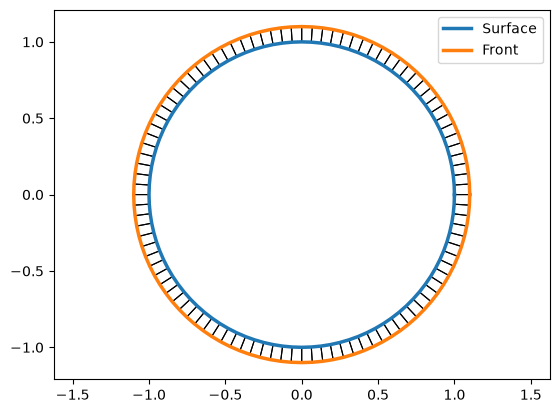

In [5]:
# Compute the front normals
normals = compute_normals(mesh, front)

# Advance the front creating new vertices based on the normals
front = advance_front(mesh, front, normals, height)

# Visualize the mesh
plot_mesh(mesh, [surface, front])

Create the second layer

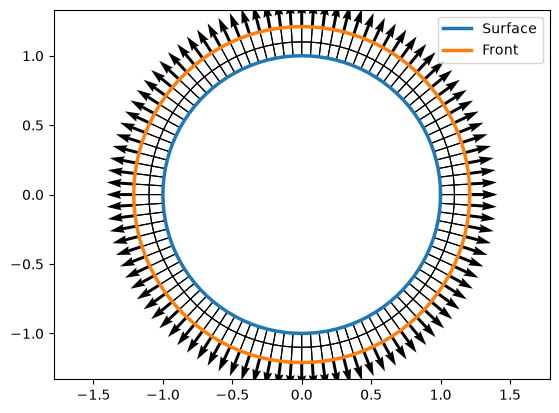

In [6]:
# Compute the front normals
normals = compute_normals(mesh, front)

# Update height
height *= growth_rate

# Advance the front creating new vertices based on the normals
front = advance_front(mesh, front, normals, height)

# Visualize the mesh, just compute the normals for the current front
normals = compute_normals(mesh, front)
plot_mesh(mesh, [surface, front], [("Front", normals)])

The layers can be created in a loop

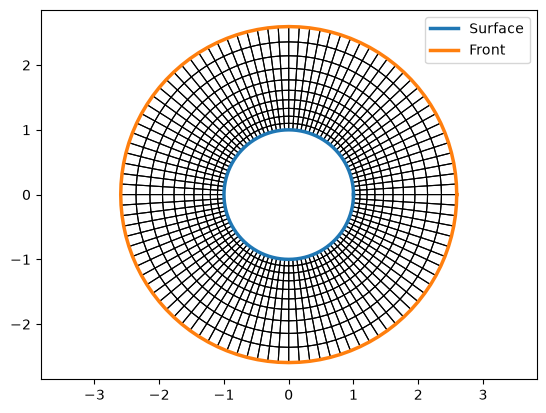

In [7]:
for _ in range(num_layers - 2):
    # Compute the front normals
    normals = compute_normals(mesh, front)

    # Update height
    height *= growth_rate

    # Advance the front creating new vertices based on the normals
    front = advance_front(mesh, front, normals, height)

# Plot final mesh
plot_mesh(mesh, [surface, front])